# IBM AML HI-Small — từ graph đến cảnh báo laundering

**Câu hỏi nghiên cứu:** Degree/PageRank, motifs và LPA có bổ sung thông tin dự đoán so với chỉ dùng giao dịch không?

Notebook chạy **toàn bộ dataset riêng này**, giữ một physical transaction index và cùng population cho mọi đối chứng. Output cuối là score/alert theo giao dịch, confusion matrix, PR/AP, review budgets và evidence có thể kiểm tra.

**Cách đọc:** mục tiêu → code tính toán → kết quả → diễn giải. Các kernel quan trọng được viết trực tiếp trong code cells, AST-matched với `.py` và được truyền vào pipeline để thực thi; helper I/O/checkpoint/guard được import ở đúng mục.

**Nhãn:** IBM `Is Laundering` được ánh xạ thành `isFraud` theo schema chung; target vẫn là laundering. Score có class weights chưa được calibrated thành xác suất. Test là **reused internal temporal holdout**, không phải untouched external benchmark.

## Pipeline thống nhất

```mermaid
flowchart TD
    R[Raw dataset riêng cho PaySim hoặc IBM] --> E[ETL / full vertices + edges]
    E --> I[Integrity + raw reconciliation + one transaction index]
    I --> A[Full analytics: Degree/PageRank + LPA + motif baseline]
    I --> H[Historical transaction prefixes]
    H --> C[Degree/PageRank snapshots]
    H --> M[Strict-past cycle/relay/history motifs]
    H --> L[LPA snapshots / community context]
    C --> F[Common feature table: one row per transaction]
    M --> F
    L --> F
    F --> V[Walk-forward: 9 families / frozen thresholds]
    V --> T[Refit through 80% / test after cutoff]
    T --> O[Predictions + PR / budgets + evidence + independent checks]
```

Full analytics phục vụ mô tả toàn graph; classifier chỉ dùng historical prefixes đúng thời điểm để tránh nhìn tương lai.

## 01 · Môi trường thực thi

Windows Python 3.12/JDK17, một workload tại một thời điểm. CPU dùng mọi logical CPU Windows cho phép; số task được giới hạn theo heap để các toán tử có thể spill. Giữ heap5 GiB/job8 GiB và khoảng8 GiB host reserve. Bảng dưới là cấu hình **thực tế** của kernel đang chạy.

In [1]:
from __future__ import annotations
from pathlib import Path
import os
import sys

os.environ['PYTHONUTF8'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'requirements.txt').exists() and (p / 'src').is_dir())
sys.path.insert(0, str(repo))
from IPython.display import display, Markdown
from src.motif.presentation import start_system_session

DATASET = 'ibm_aml'
session = start_system_session(DATASET)
spark = session.spark
display(session.runtime[session.runtime.setting.isin([
    'dataset','system','python','spark','java','master','driver_memory',
    'cpu_hard_cap_percent','max_logical_cpus','spark_task_slots','job_commit_cap_gib','pip_check'])])

[RESOURCE] One workload; CPU capacity 100%; 20 CPUs available / 20 Spark tasks; job commit cap 8.0 GiB; RAM reserve 7.9 GiB


[RESOURCE] Effective Spark local[20], heap 5120m; spill before increasing RAM


,setting,value
0,dataset,ibm_aml
1,system,Windows
2,python,3.12.10
3,spark,3.5.1
5,java,17.0.20.1
6,master,local[20]
7,driver_memory,5120m
8,pip_check,PASS
9,cpu_hard_cap_percent,100
10,max_logical_cpus,20


## 02 · Khóa protocol trước benchmark

Transaction-only luôn là baseline. C/M/L lần lượt là centrality/motif/community; 8 tổ hợp C/M/L và một novelty control tạo9 families. Cùng tree depth5, min-leaf50, seed2026. Validation ba prefix tăng dần40→50,50→65,65→80%; refit tới80%, test sau cutoff. Ngưỡng chọn bằng mean validation F1, rồi khóa. Không chọn lại bằng test.

In [2]:
import pandas as pd
from src.motif.config import FullSystemConfig, SYSTEM_FAMILY_GROUPS

config = FullSystemConfig()
display(pd.DataFrame([
    {'parameter':'motif windows (hours)','value':str(config.analysis.windows_hours)},
    {'parameter':'snapshot quantiles','value':str(config.snapshot_fractions)},
    {'parameter':'score thresholds','value':str(config.analysis.score_thresholds)},
    {'parameter':'review budgets','value':str(config.review_fractions)},
    {'parameter':'tree / leaf / seed','value':f'{config.analysis.tree_depth} / {config.analysis.minimum_leaf_rows} / {config.analysis.seed}'},
    {'parameter':'PR / LPA iterations','value':f'{config.pagerank_iterations} / {config.lpa_iterations}'}]))
display(pd.DataFrame([{'family':name,'graph_groups':', '.join(groups) or 'none'}
                      for name,groups in SYSTEM_FAMILY_GROUPS.items()]))

,parameter,value
0,motif windows (hours),"(24, 168)"
1,snapshot quantiles,"(0.2, 0.4, 0.5, 0.65, 0.8)"
2,score thresholds,"(0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3..."
3,review budgets,"(0.001, 0.005, 0.01)"
4,tree / leaf / seed,5 / 50 / 2026
5,PR / LPA iterations,10 / 5


,family,graph_groups
0,transaction_only,none
1,transaction_novelty,novelty
2,transaction_centrality,centrality
3,motif_assisted,motif
4,transaction_community,community
5,full_fusion,"centrality, motif, community"
6,without_centrality,"motif, community"
7,without_motifs,"centrality, community"
8,without_community,"centrality, motif"


## 03 · Raw → full vertices/edges → một transaction index

Raw IBM được mapping thành bank/account IDs, timestamp, amount, currency, format và target laundering. Raw timestamp mapping dùng Asia/Saigon theo ETL đã bàn giao; feature chronology dùng giá trị step nhất quán.

Kernel dưới chuẩn hóa contract và kiểm tra giá trị trước cast. `event_key` loại nhãn; các raw rows giống nhau vẫn được giữ thành các `event_id` riêng. Không downsample.

| Raw field | Graph / evaluation field |
|---|---|
| From Bank + Account | src |
| To Bank + Account | dst |
| Timestamp | step |
| Amount Paid | amount |
| Payment Currency / Receiving Currency | payment_currency / receiving_currency |
| Payment Format | type |
| Is Laundering | isFraud (laundering target) |


Nguồn đối chiếu: [src/motif/features.py](../src/motif/features.py) · `normalize_edges()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [3]:
from pyspark.sql import DataFrame, functions as F
from src.motif.config import DatasetSpec

def normalize_edges(edges: DataFrame, spec: DatasetSpec) -> DataFrame:
    """Validate physical rows once; project a dataset-independent edge contract."""
    needed = {"src", "dst", "step", "amount", "type", "isFraud"}
    if spec.has_currency:
        needed |= {"payment_currency", "receiving_currency"}
    missing = needed.difference(edges.columns)
    if missing:
        raise ValueError(f"Missing edge columns: {sorted(missing)}")
    projected = edges.select(
        F.col("src").cast("string"), F.col("dst").cast("string"),
        F.col("step").cast("long"), F.col("amount").cast("double"),
        F.col("type").cast("string"), F.col("isFraud").cast("double"),
        (F.col("payment_currency") if spec.has_currency else F.lit("PaySim unit")).alias("payment_currency"),
        (F.col("receiving_currency") if spec.has_currency else F.lit("PaySim unit")).alias("receiving_currency"),
    )
    # Validate before casts can conceal malformed labels or fractional timestamps.
    invalid_original = edges.where(
        F.col("step").isNull() | (F.col("step").cast("double") != F.col("step").cast("long"))
        | F.col("isFraud").isNull() | ~F.col("isFraud").cast("double").isin(0.0, 1.0)
    ).limit(1).count()
    invalid = projected.where(
        F.col("amount").isNull() | F.isnan("amount") | (F.abs("amount") == float("inf"))
        | (F.col("amount") < 0) | F.col("step").isNull() | F.col("isFraud").isNull()
        | F.col("src").isNull() | F.col("dst").isNull()
        | (F.trim("src") == "") | (F.trim("dst") == "")
        | F.col("type").isNull() | (F.trim("type") == "")
        | F.col("payment_currency").isNull() | F.col("receiving_currency").isNull()
        | (F.trim("payment_currency") == "") | (F.trim("receiving_currency") == "")
    ).limit(1).count()
    if invalid_original or invalid:
        raise ValueError("Invalid transaction: require finite amount >=0, integer time, nonblank keys and binary labels")
    # Content keys are stable, but identical source records deliberately share a
    # content key. event_id assigned by index_transactions preserves multiplicity.
    key_columns = sorted(needed.difference({"isFraud"}) | {"payment_currency", "receiving_currency"})
    return projected.withColumn("event_key", F.sha2(F.to_json(F.struct(*key_columns)), 256))

kernels = {'normalize_edges': normalize_edges}
print('Edge validation and label-blind content key kernel ready.')

Edge validation and label-blind content key kernel ready.


[SYSTEM] Verified resume: run_20261024T081350344149Z; unchanged source/input/config


,accounts,transactions,unique_event_ids,positive_labels,prevalence
0,518581,5078345,5078345,5177,0.001019


,event_id,src,dst,step,type,amount,payment_currency,isFraud
0,455266533376,320833_807A7CEA0,16450_807A7CE50,1662070740,Credit Card,41.72,Euro,0.0
1,455266533377,70_1004288E8,12_80CD51CC0,1662076920,Cash,8950.52,Mexican Peso,0.0
2,455266533378,111491_8060083B0,244490_81057E240,1662124560,Cash,2045.74,US Dollar,0.0
3,455266533379,21568_807F03B60,23331_808B07E90,1662689160,Cash,295.98,UK Pound,0.0
4,455266533380,220_8025BF150,16333_8111F9CC0,1662016080,Credit Card,4.14,US Dollar,0.0


Full run directory: D:\Desktop_informations\SGK năm 4\SGK kì 1 năm 4\BigData - Phong\Project_graphX\graphguard-amls-detection\results\full_system\ibm_aml\run_20261024T081350344149Z


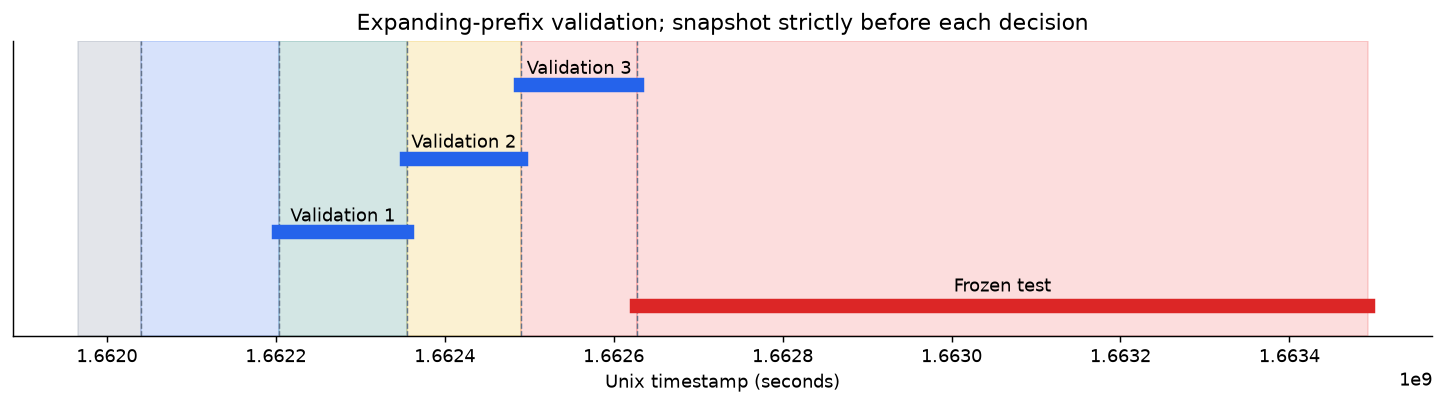

,time_block,transactions,positives,first_step,last_step,positive_rate,first_time_UTC,last_time_UTC
0,0,1013927,286.0,1661965200,1662040740,0.000282,2022-08-31 17:00:00+00:00,2022-09-01 13:59:00+00:00
1,1,1015757,761.0,1662040800,1662203520,0.000749,2022-09-01 14:00:00+00:00,2022-09-03 11:12:00+00:00
2,2,508335,699.0,1662203580,1662354720,0.001375,2022-09-03 11:13:00+00:00,2022-09-05 05:12:00+00:00
3,3,760846,809.0,1662354780,1662490020,0.001063,2022-09-05 05:13:00+00:00,2022-09-06 18:47:00+00:00
4,4,761659,823.0,1662490080,1662627900,0.001081,2022-09-06 18:48:00+00:00,2022-09-08 09:05:00+00:00
5,5,1017821,1799.0,1662627960,1663492680,0.001768,2022-09-08 09:06:00+00:00,2022-09-18 09:18:00+00:00


In [4]:
from src.motif.pipeline import start_full_system
from src.motif.presentation import plot_system_timeline

# Resume chỉ khi source/input/config và completed output hashes khớp toàn bộ.
run = start_full_system(spark, DATASET, config=config, kernels=kernels,
                        resume_from=os.environ.get('GRAPHGUARD_RESUME_RUN'))
transactions = run.table('transactions')
display(pd.DataFrame([{
    'accounts':run.record['integrity']['num_vertices'],
    'transactions':run.record['support']['n'],
    'unique_event_ids':run.record['support']['unique_ids'],
    'positive_labels':int(run.record['support']['positives']),
    'prevalence':run.record['support']['positives']/run.record['support']['n']}]))
assert run.record['support']['n'] == run.record['support']['unique_ids']
display(transactions.select('event_id','src','dst','step','type','amount','payment_currency','isFraud').limit(5).toPandas())
print('Full run directory:', run.output_dir)
display(plot_system_timeline(run))

In [5]:
from src.motif.pipeline import full_system_raw_reconciliation
from src.motif.presentation import system_phase_table

reconciliation = full_system_raw_reconciliation(run)
display(pd.DataFrame(reconciliation['tables']))
display(system_phase_table(run, 'raw_reconciliation'))

[SYSTEM] Reused verified raw_reconciliation; no computation repeated


,table,raw_minus_parquet,parquet_minus_raw,status
0,vertices,0,0,PASS
1,edges,0,0,PASS


,check,value
0,status,PASS
1,elapsed_seconds,66.024
2,average_job_cpu_percent,46.5
3,peak_job_commit_gib,5.22
4,minimum_available_ram_gib,14.4


## 04 · Full Degree/PageRank: tài khoản kết nối và hub cấu trúc

Degree đếm từng transaction edge; isolate giữ degree0. PageRank10 vòng, reset0.15; weighted edges giữ multiplicity. Backend SQL disk-checkpoint theo công thức fixed-iteration GraphX, chuẩn hóa cuối để tổng rank=N. Không diễn giải PageRank là xác suất fraud.

Hai kernel dưới được dùng cho cả full analytics và historical snapshots.

Nguồn đối chiếu: [src/paysim/metrics.py](../src/paysim/metrics.py) · `pagerank_update()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [6]:
from pyspark.sql import functions as F

def pagerank_update(ids, weights, ranks, reset_probability):
    """One directed PageRank update, preserving physical-edge multiplicity."""
    incoming = (
        weights.join(ranks.select(F.col("id").alias("src"), "pagerank"), "src")
        .groupBy("dst")
        .agg(F.sum(F.col("pagerank") * F.col("weight")).alias("incoming"))
    )
    # A vertex without incoming messages receives only the reset term.
    return (
        ids.join(incoming.withColumnRenamed("dst", "id"), "id", "left")
        .select("id", (F.lit(reset_probability) + (1-reset_probability)
                * F.coalesce(F.col("incoming"), F.lit(0.0))).alias("pagerank"))
    )

run.kernels['pagerank_update'] = pagerank_update
print('PageRank update bound to full graph and historical prefixes.')

PageRank update bound to full graph and historical prefixes.


Nguồn đối chiếu: [src/paysim/metrics.py](../src/paysim/metrics.py) · `account_degree_metrics()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [7]:
from pyspark.sql import functions as F

def account_degree_metrics(ids, edges, ranks):
    """Keep every account, including isolates; count each transaction edge."""
    incoming = edges.groupBy("dst").count().select(
        F.col("dst").alias("id"), F.col("count").alias("inDegree"))
    outgoing = edges.groupBy("src").count().select(
        F.col("src").alias("id"), F.col("count").alias("outDegree"))
    return (
        ranks.join(incoming, "id", "left").join(outgoing, "id", "left")
        .fillna(0, subset=["inDegree", "outDegree"])
        .withColumn("degree", F.col("inDegree") + F.col("outDegree"))
    )

run.kernels['account_degree_metrics'] = account_degree_metrics
print('All-account degree kernel ready, including zero-degree accounts.')

All-account degree kernel ready, including zero-degree accounts.


[SYSTEM] Reused verified centrality_full; no computation repeated


,check,value
0,status,PASS
1,elapsed_seconds,39.927
2,average_job_cpu_percent,35.67
3,accounts,518581
4,degree_sum,10156690
5,rank_sum,518581.0
6,peak_job_commit_gib,5.23
7,minimum_available_ram_gib,14.27


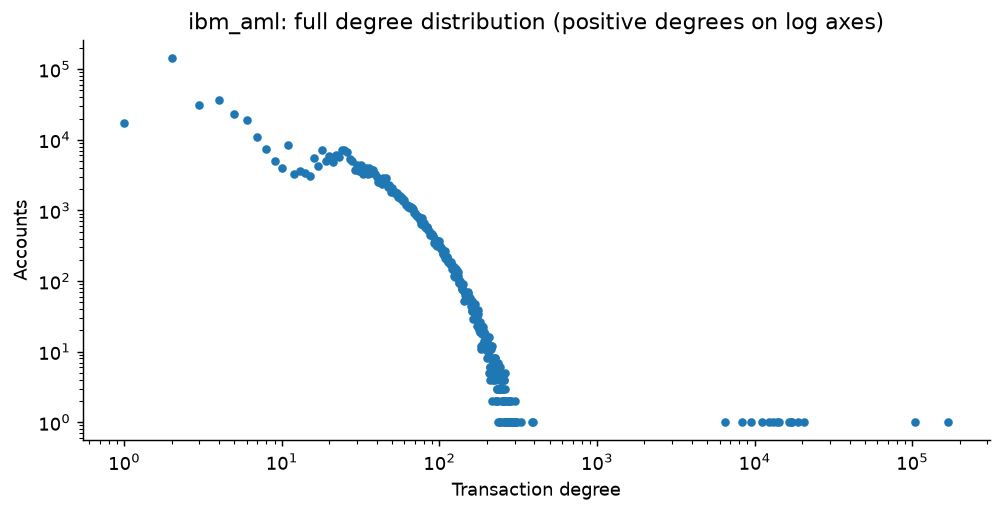

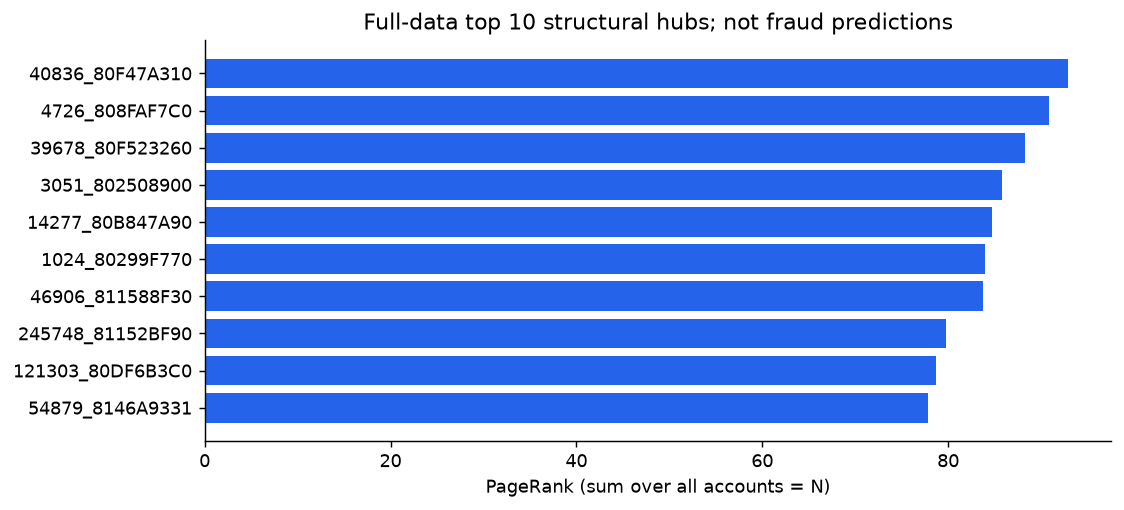

,id,pagerank,inDegree,outDegree,degree
0,40836_80F47A310,92.916825,159,2,161
1,4726_808FAF7C0,90.901724,90,1,91
2,39678_80F523260,88.309695,84,2,86
3,3051_802508900,85.792714,78,2,80
4,14277_80B847A90,84.680007,85,1,86
5,1024_80299F770,83.987381,80,2,82
6,46906_811588F30,83.774530,76,1,77
7,245748_81152BF90,79.785057,69,1,70
8,121303_80DF6B3C0,78.692572,71,2,73
9,54879_8146A9331,77.805299,83,1,84


In [8]:
from src.motif.pipeline import full_system_centrality
from src.motif.presentation import plot_system_centrality, system_phase_table

centrality = full_system_centrality(run)
assert centrality['degree_sum'] == 2 * run.record['support']['n']
assert abs(centrality['rank_sum']-centrality['accounts']) < centrality['accounts']*1e-9
display(system_phase_table(run, 'centrality_full'))
display(plot_system_centrality(run))

## 05 · Full LPA: community là bối cảnh cấu trúc

LPA5 synchronous iterations; mỗi transaction gửi message hai chiều, có trọng số multiplicity. Seed xxhash64 kiểm tra collision; tie chọn nhãn nhỏ nhất. Isolate giữ nhãn. Numeric community ID không phải class fraud hoặc feature.

Một partition có nhiều cross edges hoặc internal edges=0 vẫn là output thuật toán cần báo thật; hiệu quả dự đoán phải kiểm tra bằng ablation.

Nguồn đối chiếu: [src/paysim/community_detection.py](../src/paysim/community_detection.py) · `lpa_update()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [9]:
from pyspark.sql import functions as F

def lpa_update(links, labels):
    """Synchronous weighted neighbor voting; deterministic minimum-label tie."""
    messages = links.join(labels.select(
        F.col("id").alias("neighbor"), F.col("label").alias("neighbor_label")), "neighbor")
    votes = messages.groupBy("id", "neighbor_label").agg(F.sum("multiplicity").alias("votes"))
    # Lexicographic min(-votes, label) = most votes, then smallest label.
    winner = votes.groupBy("id").agg(F.min(F.struct(
        (-F.col("votes")).alias("negative_votes"),
        F.col("neighbor_label").alias("label"))).alias("winner"))
    winner = winner.select("id", F.col("winner.label").alias("new_label"))
    # Isolates receive no message and keep their current label.
    return labels.join(winner, "id", "left").select(
        "id", F.coalesce("new_label", "label").alias("label"))

run.kernels['lpa_update'] = lpa_update
print('Synchronous modal-neighbor LPA kernel bound; deterministic tie rule.')

Synchronous modal-neighbor LPA kernel bound; deterministic tie rule.


[SYSTEM] Reused verified communities_full; no computation repeated


,check,value
0,status,PASS
1,elapsed_seconds,69.736
2,average_job_cpu_percent,38.32
3,communities,314722
4,accounts,518581
5,positives,5177
6,internal_edges,852930
7,cross_edges,4225415
8,peak_job_commit_gib,5.24
9,minimum_available_ram_gib,14.27


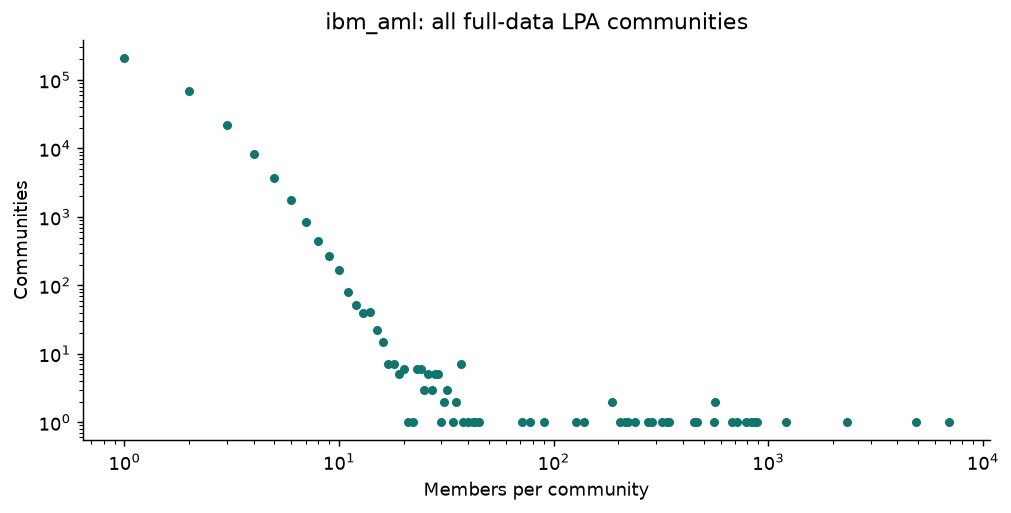

,label,member_count,total_tx_count,positive_tx_count,internal_tx_count,cross_tx_count
0,2841208552804025435,6935,42119,69,8289,33830
1,-6017008472124481862,4870,32202,45,6293,25909
2,-1845136380396678331,2327,179865,248,2278,177587
3,1645034660210658271,1212,109143,166,902,108241
4,-403586342733232231,883,5586,2,1050,4536
5,-8152616635486292743,854,6204,7,1170,5034
6,-7416694367604068795,828,6278,4,1012,5266
7,-735310874234786089,788,4757,14,1142,3615
8,-6006891417238418498,716,5108,6,917,4191
9,5480051028422924661,676,4193,4,767,3426


In [10]:
from src.motif.pipeline import full_system_communities
from src.motif.presentation import plot_system_communities, system_phase_table

community_checks = full_system_communities(run)
display(system_phase_table(run, 'communities_full'))
community_view = plot_system_communities(run)
columns = [name for name in ['label','member_count','total_tx_count','positive_tx_count','internal_tx_count','cross_tx_count']
           if name in community_view.columns]
display(community_view[columns])

## 06 · Motif baseline của đề: tìm cấu trúc trước, đối chiếu nhãn sau

Baseline được giữ để giải thích xuất phát điểm. IBM có truy vấn trên subgraph đã biết nhãn laundering: đó là **retrospective label audit**, không được đưa thành inference feature. PaySim kiểm tra directed3-cycle và relay TRANSFER→CASH_OUT theo điều kiện đề; same-hour pairs còn mơ hồ thứ tự.

Causal feature construction ở mục tiếp theo độc lập với việc lọc label của baseline.

Nguồn đối chiếu: [src/motif/toy_cycle.py](../src/motif/toy_cycle.py) · `find_three_node_cycles()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [11]:
from graphframes import GraphFrame
from pyspark.sql import DataFrame, functions as F
from src.motif.toy_cycle import MOTIF_PATTERN

def find_three_node_cycles(graph: GraphFrame) -> DataFrame:
    """Chạy đúng motif đã giao và loại các đường đóng có đỉnh trùng nhau."""
    return (
        graph.find(MOTIF_PATTERN)
        .where(
            (F.col("a.id") != F.col("b.id"))
            & (F.col("b.id") != F.col("c.id"))
            & (F.col("c.id") != F.col("a.id"))
        )
    )

run.kernels['find_three_node_cycles'] = find_three_node_cycles
print('GraphFrames pattern:', MOTIF_PATTERN)

GraphFrames pattern: (a)-[e1]->(b);(b)-[e2]->(c);(c)-[e3]->(a)


In [12]:
from src.motif.pipeline import full_system_baseline

baseline = full_system_baseline(run)
display(baseline.summary.T.rename(columns={0:'observed'}))
display(baseline.examples.head(5))

[SYSTEM] Reused verified motif_baseline; no computation repeated


,observed
dataset,ibm_aml
fraud_edges,5177
label_audit_raw_cycles,7473
directed_account_cycles,54
transaction_combinations,2491
USD_above_10000_cycles,0


,a,b,c,transaction_combinations
0,119_811C597B0,222_811B83280,48309_811C599A0,490
1,148350_811FFF630,148350_812D0C3C0,50528_812D0C600,360
2,119_811C597B0,150240_812D22980,48309_811C599A0,300
3,119_811C597B0,48309_811C599A0,150240_812D22980,280
4,119_811C597B0,222_811B83280,150240_812D22980,245


## 07 · Causal motifs: mỗi giao dịch chỉ nhìn lịch sử

Historical event tại s được dùng cho quyết định tại t khi **s<t≤s+H**. Các giao dịch cùng timestamp không cấp lịch sử cho nhau. Chỉ đếm cấu trúc đủ điều kiện; mọi transaction, kể cả không có motif, self-loop/FX, vẫn giữ trong population.

Phần code chia theo expiry-prefix sums, role histories, reciprocal và chronological3-cycle. Helpers và witness IDs không trở thành model feature.

Nguồn đối chiếu: [src/motif/features.py](../src/motif/features.py) · `_sweep_counts()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [13]:
from pyspark.sql import DataFrame, Window, functions as F
from src.motif.config import DatasetSpec

def _sweep_counts(buckets: DataFrame, keys: list[str], values: list[str],
                  spec: DatasetSpec, windows_hours: tuple[int, ...]) -> DataFrame:
    """Exact rolling counts using +count / -count expiry events and prefix sums.

    A transaction at integer time s contributes at query t iff s<t<=s+H.
    Thus activate at s+1, expire at s+H+1. Query markers have zero delta.
    All ties are aggregated before the unbounded cumulative sum. This avoids
    Spark's bounded SlidingWindowFunctionFrame rescanning high-degree buffers.
    A key observed at only one timestamp has zero strict-past counts at every
    query. Omit those keys before expanding markers; callers fill missing zero
    histories after their left join. This saves most PaySim account/pair work.
    """
    active_keys = buckets.groupBy(*keys).count().where(F.col("count") > 1).select(*keys)
    buckets = buckets.join(active_keys, keys, "left_semi")
    columns = [f"{value}_{hours}h" for hours in windows_hours for value in values]
    zero = F.lit(0).cast("long")
    entries = [F.struct(F.col("step").cast("long").alias("_time"), F.lit(1).alias("_query"),
                        *[zero.alias(name) for name in columns])]
    for hours in windows_hours:
        steps = hours * 3600 // spec.seconds_per_step
        for shift, sign in ((1, 1), (steps + 1, -1)):
            deltas = [(F.col(value) * sign if h == hours else zero).alias(f"{value}_{h}h")
                      for h in windows_hours for value in values]
            entries.append(F.struct((F.col("step").cast("long") + shift).alias("_time"),
                                    F.lit(0).alias("_query"), *deltas))
    expanded = buckets.select(*keys, F.explode(F.array(*entries)).alias("_marker")).select(*keys, "_marker.*")
    grid = expanded.groupBy(*keys, "_time").agg(F.max("_query").alias("_query"),
                                               *[F.sum(name).alias(name) for name in columns])
    prefix = Window.partitionBy(*keys).orderBy("_time").rowsBetween(Window.unboundedPreceding, Window.currentRow)
    # Select creates a single WindowExec for every cumulative sum.
    cumulative = grid.select(*keys, "_time", "_query", *[F.sum(name).over(prefix).alias(name) for name in columns])
    return cumulative.where(F.col("_query") == 1).select(*keys, F.col("_time").alias("step"), *columns)

print('Exact history window: activate at s+1, expire at s+H+1.')

Exact history window: activate at s+1, expire at s+H+1.


Nguồn đối chiếu: [src/motif/features.py](../src/motif/features.py) · `build_star_features()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [14]:
from src.motif.evaluation import require_unlabelled

def build_star_features(features: DataFrame, spec: DatasetSpec, windows_hours: tuple[int, ...]) -> DataFrame:
    """Role volumes before subtracting same-partner paths in build_motif_features.

    Star witnesses are resolved on demand with resolve_star_witness; computing
    min/max partner in every bounded frame is quadratic at large IBM hubs.
    """
    require_unlabelled(features)
    eligible = features.where((F.col("src") != F.col("dst")) & (F.col("amount") > 0)
                              & (F.col("payment_currency") == F.col("receiving_currency")))
    outgoing = eligible.select("event_id", "step", "type", "payment_currency",
        F.col("src").alias("account"), F.lit(0).alias("direction"))
    incoming = eligible.select("event_id", "step", "type", "payment_currency",
        F.col("dst").alias("account"), F.lit(1).alias("direction"))
    roles = outgoing.unionByName(incoming)
    is_in = F.col("direction") == 1
    relay_type = (F.col("type") == "TRANSFER") if spec.name == "paysim" else F.lit(True)
    keys = ["account", "payment_currency"]
    buckets = roles.groupBy(*keys, "step").agg(
        F.sum(F.when(is_in, 1).otherwise(0)).alias("incoming"),
        F.sum(F.when(~is_in, 1).otherwise(0)).alias("outgoing"),
        F.sum(F.when(is_in & relay_type, 1).otherwise(0)).alias("relay_incoming"))
    counts = _sweep_counts(buckets, keys, ["incoming", "outgoing", "relay_incoming"], spec, windows_hours)
    joined = roles.join(counts, [*keys, "step"])
    is_sender = F.col("direction") == 0
    relay_current = is_sender & ((F.col("type") == "CASH_OUT") if spec.name == "paysim" else F.lit(True))
    expressions = {}
    for hours in windows_hours:
        inc, out = F.col(f"incoming_{hours}h"), F.col(f"outgoing_{hours}h")
        expressions.update({
            f"sender_in_{hours}h": F.when(is_sender, inc),
            f"sender_out_{hours}h": F.when(is_sender, out),
            f"receiver_in_{hours}h": F.when(~is_sender, inc),
            f"receiver_out_{hours}h": F.when(~is_sender, out),
            f"fanin_{hours}h": F.when(~is_sender, inc),
            f"fanout_{hours}h": F.when(is_sender, out),
            f"relay_{hours}h": F.when(relay_current, F.col(f"relay_incoming_{hours}h")),
        })
    projected = joined.select("event_id", *[expression.alias(name) for name, expression in expressions.items()])
    return projected.groupBy("event_id").agg(*[F.max(name).alias(name) for name in expressions])

print('Fan-in/out and relay history kernels ready.')

Fan-in/out and relay history kernels ready.


Nguồn đối chiếu: [src/motif/features.py](../src/motif/features.py) · `build_reciprocal_features()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [15]:
from pyspark.sql import Window, functions as F
from src.motif.evaluation import require_unlabelled

def build_reciprocal_features(features: DataFrame, spec: DatasetSpec, windows_hours: tuple[int, ...]) -> DataFrame:
    """Counts from expiry-prefix sums; latest opposite witness from one prefix max."""
    require_unlabelled(features)
    pairs = features.where((F.col("src") != F.col("dst")) & (F.col("amount") > 0)
                            & (F.col("payment_currency") == F.col("receiving_currency")))
    pairs = pairs.withColumn("_low", F.least("src", "dst")).withColumn("_high", F.greatest("src", "dst"))
    direction = F.col("src") == F.col("_low")
    relay_type = (F.col("type") == "TRANSFER") if spec.name == "paysim" else F.lit(True)
    keys = ["_low", "_high", "payment_currency"]
    buckets = pairs.groupBy(*keys, "step").agg(
        F.sum(F.when(direction, 1).otherwise(0)).alias("forward"),
        F.sum(F.when(~direction, 1).otherwise(0)).alias("backward"),
        F.sum(F.when(direction & relay_type, 1).otherwise(0)).alias("forward_relay"),
        F.sum(F.when(~direction & relay_type, 1).otherwise(0)).alias("backward_relay"))
    counts = _sweep_counts(buckets, keys, ["forward", "backward", "forward_relay", "backward_relay"], spec, windows_hours)
    history = Window.partitionBy(*keys).orderBy("step").rangeBetween(Window.unboundedPreceding, -1)
    # Remove one-timestamp pairs before sorting witness histories too. All
    # timestamps of a retained pair remain present, including its first event.
    active_pairs = pairs.join(counts, [*keys, "step"])
    latest = active_pairs.withColumn("_forward_event", F.max(F.when(direction, F.struct("step", "event_id"))).over(history))
    latest = latest.withColumn("_backward_event", F.max(F.when(~direction, F.struct("step", "event_id"))).over(history))
    result = latest
    opposite = F.when(direction, F.col("_backward_event")).otherwise(F.col("_forward_event"))
    names = []
    for hours in windows_hours:
        fields = {
            f"same_partner_count_{hours}h": F.when(direction, F.col(f"forward_{hours}h")).otherwise(F.col(f"backward_{hours}h")),
            f"reverse_relay_count_{hours}h": F.when(direction, F.col(f"backward_relay_{hours}h")).otherwise(F.col(f"forward_relay_{hours}h")),
            f"reciprocal_{hours}h": F.when(direction, F.col(f"backward_{hours}h")).otherwise(F.col(f"forward_{hours}h")).cast("double"),
            f"reciprocal_witness_{hours}h": F.when(
                F.col("step") - opposite["step"] <= hours * 3600 // spec.seconds_per_step, opposite["event_id"]),
        }
        for name, expression in fields.items():
            result = result.withColumn(name, expression)
            names.append(name)
    return result.select("event_id", *names)

print('Reciprocal and same-partner histories ready; equal timestamps excluded.')

Reciprocal and same-partner histories ready; equal timestamps excluded.


Nguồn đối chiếu: [src/ibm_aml/motif_finding.py](../src/ibm_aml/motif_finding.py) · `find_topological_cycles()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [16]:
from graphframes import GraphFrame
from src.motif.evaluation import require_unlabelled

def find_topological_cycles(vertices: DataFrame, features: DataFrame) -> DataFrame:
    """Enumerate directed account triples once, without labels or amounts.

    Collapsing parallel edges *before* motif matching avoids multiplying every
    historical transaction combination during the topology discovery stage.
    """
    require_unlabelled(features)
    topology = features.where(F.col("src") != F.col("dst")).select("src", "dst").distinct()
    matches = find_three_node_cycles(GraphFrame(vertices.select("id"), topology))
    return matches.where(
        (F.col("a.id") < F.col("b.id")) & (F.col("a.id") < F.col("c.id"))
    ).selectExpr("a.id a", "b.id b", "c.id c")

print('Cycle topology discovery collapses parallel edges before matching.')

Cycle topology discovery collapses parallel edges before matching.


Nguồn đối chiếu: [src/ibm_aml/motif_finding.py](../src/ibm_aml/motif_finding.py) · `build_temporal_cycle_features()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [17]:
from pyspark.sql import DataFrame, functions as F
from src.motif.evaluation import require_unlabelled

def build_temporal_cycle_features(topology: DataFrame, features: DataFrame) -> DataFrame:
    """All three rotations, but only strictly chronological same-currency cycles.

    The last edge is the decision event; the other two are already observable.
    No currency conversion is inferred. FX edges and equal timestamps are
    excluded explicitly. Each returned row is evidence, not an independent TP.
    """
    require_unlabelled(features)
    edges = features.where(
        (F.col("src") != F.col("dst")) & (F.col("amount") > 0)
        & (F.col("payment_currency") == F.col("receiving_currency"))
    ).select("event_id", "src", "dst", "step", "amount", "payment_currency")
    result = None
    for rotation in range(3):
        names = ["a", "b", "c"]
        order = names[rotation:] + names[:rotation]
        query = topology.select(*(F.col(old).alias(new) for old, new in zip(order, names)))
        query = query.join(edges.alias("x"), (F.col("a") == F.col("x.src")) & (F.col("b") == F.col("x.dst")))
        query = query.join(edges.alias("y"),
            (F.col("b") == F.col("y.src")) & (F.col("c") == F.col("y.dst"))
            & (F.col("x.payment_currency") == F.col("y.payment_currency"))
            & (F.col("x.step") < F.col("y.step")))
        query = query.join(edges.alias("z"),
            (F.col("c") == F.col("z.src")) & (F.col("a") == F.col("z.dst"))
            & (F.col("x.payment_currency") == F.col("z.payment_currency"))
            & (F.col("y.step") < F.col("z.step")))
        flat = query.select(
            "a", "b", "c", F.col("z.event_id").alias("event_id"),
            F.col("x.event_id").alias("first_event_id"), F.col("y.event_id").alias("second_event_id"),
            F.col("x.step").alias("first_step"), F.col("y.step").alias("second_step"),
            F.col("z.step").alias("step"), F.col("x.payment_currency").alias("payment_currency"),
            F.col("x.amount").alias("first_amount"), F.col("y.amount").alias("second_amount"),
            F.col("z.amount").alias("amount"),
            (F.col("z.step") - F.col("x.step")).alias("gap_seconds"),
            F.least("x.amount", "y.amount", "z.amount").alias("minimum_cycle_amount"),
            (F.least("x.amount", "y.amount", "z.amount") / F.greatest(
                "x.amount", "y.amount", "z.amount")).alias("amount_ratio"),
        )
        result = flat if result is None else result.unionByName(flat)
    return result

print('Cycle evidence requires x.step < y.step < closing.step and identical payment currency.')

Cycle evidence requires x.step < y.step < closing.step and identical payment currency.


Nguồn đối chiếu: [src/motif/features.py](../src/motif/features.py) · `materialize_motif_stage()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [18]:
from src.motif.features import temporary_motif_directory

def materialize_motif_stage(frame, directory, name):
    """Truncate SQL lineage on disk, never cache deserialized UnsafeRows."""
    from pathlib import Path
    path = Path(directory) / name
    frame.write.parquet(str(path))
    return frame.sparkSession.read.parquet(str(path))

print('Motif intermediates are Parquet-backed; no deserialized localCheckpoint cache.')

Motif intermediates are Parquet-backed; no deserialized localCheckpoint cache.


Nguồn đối chiếu: [src/motif/features.py](../src/motif/features.py) · `build_motif_features()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [19]:
from functools import partial
from src.motif.features import motif_numeric_columns
from src.motif.evaluation import require_unlabelled

def build_motif_features(features: DataFrame, vertices: DataFrame, spec: DatasetSpec,
                         windows_hours: tuple[int, ...], *, cycle_builder=None,
                         topology_builder=None, checkpoint_dir=None) -> DataFrame:
    """Label-blind motifs with disk-backed stages and bounded heap residency."""
    require_unlabelled(features)
    from src.ibm_aml.motif_finding import build_temporal_cycle_features, find_topological_cycles
    root = checkpoint_dir or temporary_motif_directory()
    print("Features: star histories via expiry-prefix sums (disk checkpoint)", flush=True)
    stars = materialize_motif_stage(build_star_features(features, spec, windows_hours), root, "stars")
    print("Features: reciprocal and same-partner histories (disk checkpoint)", flush=True)
    reciprocal = materialize_motif_stage(build_reciprocal_features(features, spec, windows_hours), root, "reciprocal")
    combined = features.join(stars, "event_id", "left").join(reciprocal, "event_id", "left")
    for hours in windows_hours:
        # A->B->A is reciprocal, not a relay involving three distinct accounts.
        for family, subtract in (("fanin", "same_partner_count"), ("fanout", "same_partner_count"),
                                 ("relay", "reverse_relay_count")):
            combined = combined.withColumn(f"{family}_{hours}h", F.greatest(
                F.coalesce(F.col(f"{family}_{hours}h"), F.lit(0))
                - F.coalesce(F.col(f"{subtract}_{hours}h"), F.lit(0)), F.lit(0)))
    print("Features: directed topology and chronological cycle evidence (disk checkpoint)", flush=True)
    topology = materialize_motif_stage(
        (topology_builder or find_topological_cycles)(vertices, features), root, "topology")
    evidence = (cycle_builder or build_temporal_cycle_features)(topology, features).withColumn(
        "gap_seconds", F.col("gap_seconds") * spec.seconds_per_step
    ).where(F.col("gap_seconds") <= max(windows_hours) * 3600)
    cycles = evidence.groupBy("event_id").agg(
        F.count("*").cast("double").alias("cycle3_count"),
        F.max("amount_ratio").alias("cycle3_best_ratio"),
        F.min("gap_seconds").alias("cycle3_min_gap_seconds"),
        F.min(F.struct("first_event_id", "second_event_id")).alias("cycle3_witness"))
    # Ratio/gap extrema may come from different paths; witness is one real path.
    numeric = motif_numeric_columns(windows_hours)
    result = combined.join(cycles, "event_id", "left").fillna(0, subset=numeric)
    return materialize_motif_stage(result, root, "features")

run.kernels['build_motif_features'] = partial(
    build_motif_features, cycle_builder=build_temporal_cycle_features,
    topology_builder=find_topological_cycles)
print('Visible motif kernels connected to the full pipeline.')

Visible motif kernels connected to the full pipeline.


[SYSTEM] Reused verified motif_features; no computation repeated


,check,value
0,status,PASS
1,elapsed_seconds,149.841
2,average_job_cpu_percent,62.5
3,rows,5078345
4,unique_ids,5078345
5,peak_job_commit_gib,6.21
6,minimum_available_ram_gib,13.39


[SYSTEM] Reused verified motif_benchmark; no computation repeated


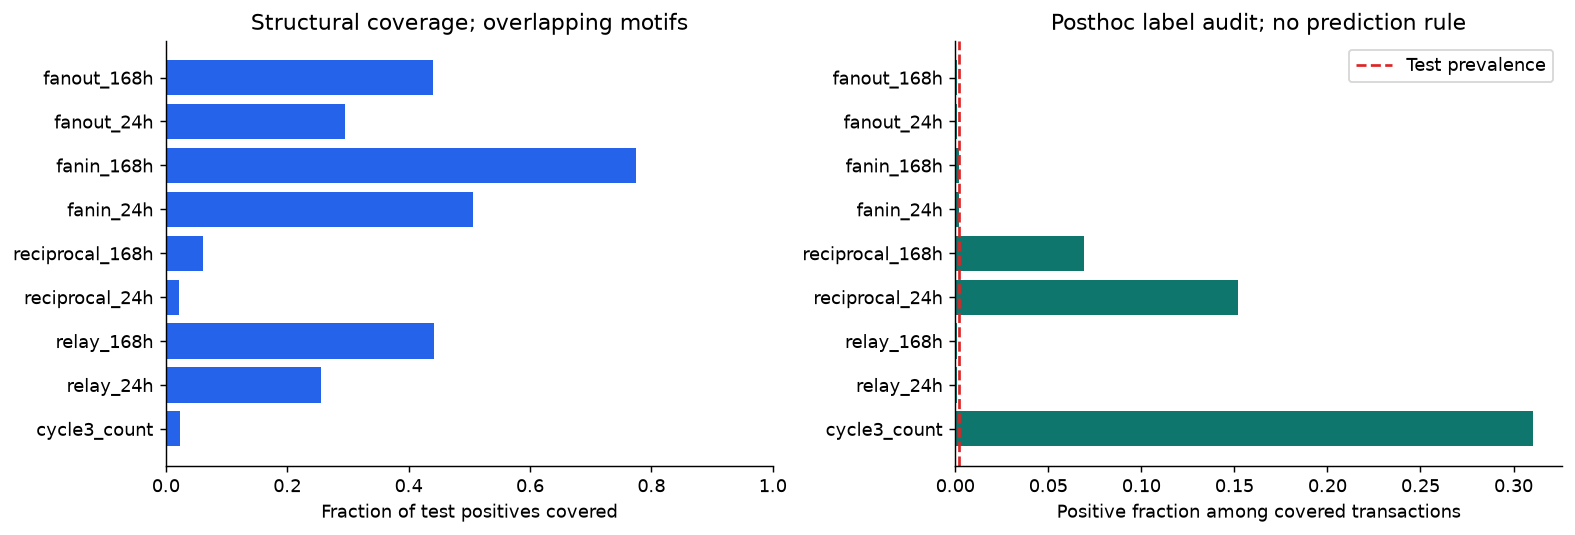

,motif,covered_transactions,covered_positives,positive_coverage,positive_fraction_when_present
9,cycle3_count,132,41,0.022790,0.310606
10,relay_24h,599171,461,0.256253,0.000769
11,relay_168h,740099,795,0.441912,0.001074
12,reciprocal_24h,257,39,0.021679,0.151751
13,reciprocal_168h,1579,109,0.060589,0.069031
14,fanin_24h,427877,909,0.505281,0.002124
15,fanin_168h,706216,1395,0.775431,0.001975
16,fanout_24h,608459,532,0.295720,0.000874
17,fanout_168h,709096,791,0.439689,0.001116


In [20]:
from src.motif.pipeline import full_system_motif_features, full_system_motif_benchmark
from src.motif.presentation import system_phase_table, plot_system_motif_coverage

motif_checks = full_system_motif_features(run)
assert motif_checks['rows'] == motif_checks['unique_ids'] == run.record['support']['n']
display(system_phase_table(run, 'motif_features'))
coverage = full_system_motif_benchmark(run)
display(plot_system_motif_coverage(run))

## 08 · Historical prefixes → một feature table chung

Full analytics ở trên không được join vào mọi transaction. Mỗi block dùng snapshot đã hoàn tất trước quyết định; các training rows cũng tuân thủ điều này. Block warm-up trước20% có C/L bằng0 với unseen flags; motif vẫn có strict-past history.

Historical PageRank/LPA có lag đã khai báo; motif có thể dùng giao dịch trước đó trong cùng block. Không sử dụng label để tạo snapshot/community statistics.

Nguồn đối chiếu: [src/motif/pipeline.py](../src/motif/pipeline.py) · `historical_system_snapshot()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [21]:
from pathlib import Path
from src.motif.config import DATASETS
from pyspark.sql import functions as F

def historical_system_snapshot(run, cutoff, directory):
    """Label-blind historical graph; same PageRank/LPA backends as full outputs."""
    from src.motif.evaluation import require_unlabelled
    from src.paysim.metrics import dataframe_pagerank
    from src.paysim.community_detection import dataframe_lpa
    edges = run.table("transactions").where(F.col("step") <= cutoff).select("src", "dst")
    require_unlabelled(edges)
    ids = edges.select(F.col("src").alias("id")).unionByName(edges.select(F.col("dst").alias("id"))).distinct()
    ranks = dataframe_pagerank(ids, edges, Path(directory)/"pagerank", run.config.pagerank_iterations,
                              update=run.kernels.get("pagerank_update"))
    labels = dataframe_lpa(ids, edges, Path(directory)/"lpa", run.config.lpa_iterations,
                           update=run.kernels.get("lpa_update"))
    incoming = edges.groupBy("dst").count().select(F.col("dst").alias("id"), F.col("count").alias("inDegree"))
    outgoing = edges.groupBy("src").count().select(F.col("src").alias("id"), F.col("count").alias("outDegree"))
    sizes = labels.groupBy("label").agg(F.count("*").alias("community_size"))
    links = edges.join(labels.select(F.col("id").alias("src"), F.col("label").alias("s")), "src").join(
        labels.select(F.col("id").alias("dst"), F.col("label").alias("d")), "dst")
    stats = links.groupBy("s").agg(F.count("*").alias("community_out_transactions"),
        F.avg((F.col("s")!=F.col("d")).cast("double")).alias("community_cross_fraction")).withColumnRenamed("s", "label")
    return (labels.join(sizes, "label").join(stats, "label", "left").join(ranks, "id").join(incoming, "id", "left")
        .join(outgoing, "id", "left").fillna(0).withColumn("degree", F.col("inDegree")+F.col("outDegree"))
        .withColumnRenamed("label", "community_key").withColumn("as_of_step", F.lit(int(cutoff)).cast("long")))

run.kernels['historical_system_snapshot'] = historical_system_snapshot
print('Historical graph uses transactions at or before its cutoff; decision blocks follow strictly later.')

Historical graph uses transactions at or before its cutoff; decision blocks follow strictly later.


Nguồn đối chiếu: [src/motif/pipeline.py](../src/motif/pipeline.py) · `join_system_snapshot()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [22]:
from pyspark.sql import functions as F

def join_system_snapshot(transactions, snapshot):
    """Join one snapshot to a strictly later block without changing its rows."""
    from src.motif.config import CENTRALITY_COLUMNS, COMMUNITY_COLUMNS
    from src.motif.evaluation import require_unlabelled
    require_unlabelled(transactions)
    names = ["inDegree", "outDegree", "degree", "pagerank", "community_size", "community_cross_fraction", "community_out_transactions"]
    result = transactions
    if snapshot is None:
        for name in [*CENTRALITY_COLUMNS, *COMMUNITY_COLUMNS]:
            result = result.withColumn(name, F.lit(0.0))
        return result.withColumn("snapshot_as_of", F.lit(None).cast("long"))
    require_unlabelled(snapshot)
    cuts = snapshot.select("as_of_step").distinct().limit(2).collect()
    if len(cuts) != 1 or transactions.where(F.col("step") <= cuts[0].as_of_step).limit(1).count():
        raise ValueError("Every decision row must strictly follow one snapshot cutoff")
    for side in ("src", "dst"):
        lookup = snapshot.select(F.col("id").alias(side), F.lit(1.0).alias(side+"_seen"),
            F.col("community_key").alias(side+"_community_key"), *[F.col(n).cast("double").alias(side+"_"+n) for n in names])
        result = result.join(lookup, side, "left")
    seen = (F.coalesce(F.col("src_seen"), F.lit(0))==1) & (F.coalesce(F.col("dst_seen"), F.lit(0))==1)
    result = result.withColumn("community_endpoints_seen", seen.cast("double")).withColumn(
        "same_community", (seen & (F.col("src_community_key")==F.col("dst_community_key"))).cast("double"))
    return result.fillna(0, subset=[*CENTRALITY_COLUMNS, *COMMUNITY_COLUMNS]).drop("src_community_key", "dst_community_key").withColumn(
        "snapshot_as_of", F.lit(int(cuts[0].as_of_step)).cast("long"))

run.kernels['join_system_snapshot'] = join_system_snapshot
print('Causal join kernel rejects any decision at or before its snapshot cutoff.')

Causal join kernel rejects any decision at or before its snapshot cutoff.


In [23]:
from src.motif.pipeline import full_system_feature_table
from src.motif.presentation import system_phase_table

feature_checks = full_system_feature_table(run)
assert feature_checks['rows'] == feature_checks['unique_ids'] == run.record['support']['n']
assert feature_checks['future_snapshot_rows'] == 0
features = run.table('features')
display(system_phase_table(run, 'common_features'))
display(features.select('event_id','step','snapshot_as_of','src_seen','dst_seen',
                        'src_degree','src_pagerank','same_community','relay_24h','cycle3_count').limit(5).toPandas())

[SYSTEM] Reused verified common_features; no computation repeated


,check,value
0,status,PASS
1,elapsed_seconds,749.761
2,average_job_cpu_percent,41.18
3,rows,5078345
4,unique_ids,5078345
5,future_snapshot_rows,0
6,peak_job_commit_gib,6.27
7,minimum_available_ram_gib,13.39


,event_id,step,snapshot_as_of,src_seen,dst_seen,src_degree,src_pagerank,same_community,relay_24h,cycle3_count
0,532575953354,1662743160,1662627900,1.0,1.0,9.0,0.222679,0.0,0,0.0
1,128849053906,1662657420,1662627900,1.0,1.0,11.0,0.311432,0.0,0,0.0
2,343597409706,1662695340,1662627900,1.0,1.0,10862.0,5.008456,0.0,21,0.0
3,103079245549,1662695280,1662627900,1.0,1.0,10862.0,5.008456,0.0,21,0.0
4,214748381665,1662756240,1662627900,1.0,1.0,10862.0,5.008456,0.0,38,0.0


## 09 · Feature fusion và cùng một mô hình đối chứng

Một training prefix dùng chung q90 amount scales theo currency/type, category indexer và truth join cho9 trees. Chỉ feature allowlist khác nhau. Class weight sqrt(negative/positive); cây depth5 giúp đọc được quyết định. Không thêm balance cuối kỳ, account IDs, witness IDs hay labels vào features.

Nguồn đối chiếu: [src/motif/modeling.py](../src/motif/modeling.py) · `_prepare_amounts()`; [src/motif/modeling.py](../src/motif/modeling.py) · `family_feature_names()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [24]:
from src.motif.config import CENTRALITY_COLUMNS, COMMUNITY_COLUMNS, SYSTEM_FAMILY_GROUPS
from src.motif.features import motif_numeric_columns
from pyspark.sql import functions as F

def _prepare_amounts(features: DataFrame, scales: DataFrame) -> DataFrame:
    """Use training q90 of each currency/type; never compare nominal currencies."""
    joined = features.join(scales, ["payment_currency", "type"], "left")
    denominator = F.greatest(F.coalesce(F.col("training_q90"), F.lit(1.0)), F.lit(1e-12))
    return joined.withColumn("scaled_amount", F.log1p(F.least(F.col("amount") / denominator, F.lit(1e12)))).withColumn(
        "unseen_amount_group", F.col("training_q90").isNull().cast("double")
    ).withColumn("fx_payment", (F.col("payment_currency") != F.col("receiving_currency")).cast("double"))

def family_feature_names(family, config):
    # Explicit allowlists exclude label, witness/account IDs and future data.
    names = ["type_index", "currency_index", "scaled_amount", "unseen_amount_group", "fx_payment"]
    groups = {"motif": motif_numeric_columns(config.windows_hours),
              "centrality": CENTRALITY_COLUMNS, "community": COMMUNITY_COLUMNS,
              "novelty": ["src_seen", "dst_seen"]}
    for group in SYSTEM_FAMILY_GROUPS[family]:
        names += groups[group]
    return names

display(pd.DataFrame([{'family':name,'groups':', '.join(SYSTEM_FAMILY_GROUPS[name]) or 'none',
                       'feature_count':len(family_feature_names(name,config.analysis))}
                      for name in SYSTEM_FAMILY_GROUPS]))

,family,groups,feature_count
0,transaction_only,none,5
1,transaction_novelty,novelty,7
2,transaction_centrality,centrality,15
3,motif_assisted,motif,24
4,transaction_community,community,13
5,full_fusion,"centrality, motif, community",42
6,without_centrality,"motif, community",32
7,without_motifs,"centrality, community",23
8,without_community,"centrality, motif",34


Nguồn đối chiếu: [src/motif/modeling.py](../src/motif/modeling.py) · `prepare_training_prefix()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [25]:
import math
from pyspark.ml.feature import StringIndexer
from src.motif.modeling import PreparedTraining
from src.motif.evaluation import require_unlabelled

def prepare_training_prefix(features, truth, train_end, config, *, spill_training=True):
    """Fit preprocessing only on this prefix, then materialize once on disk."""
    from pyspark import StorageLevel
    require_unlabelled(features)
    train = features.where(F.col("step") <= train_end)
    scales = train.where(F.col("amount") > 0).groupBy("payment_currency", "type").agg(
        F.percentile_approx("amount", 0.9, 10_000).alias("training_q90")
    ).persist(StorageLevel.DISK_ONLY)
    scales.count()
    labelled = _prepare_amounts(train, scales).join(truth.select("event_id", "isFraud"), "event_id")
    support = labelled.agg(F.count("*").alias("n"), F.sum("isFraud").alias("p")).first()
    n, p = int(support.n), int(support.p or 0)
    weight = math.sqrt((n-p)/p) if 0 < p < n else 1.0
    metadata = {"train_end": int(train_end), "rows": n, "fraud": p,
                "positive_class_weight": weight, "status": "fitted" if 0 < p < n else "abstain: one training class"}
    indexer = StringIndexer(inputCols=["type", "payment_currency"], outputCols=["type_index", "currency_index"],
                           stringOrderType="alphabetAsc", handleInvalid="keep").fit(labelled)
    encoded = indexer.transform(labelled).withColumn(
        "_weight", F.when(F.col("isFraud") == 1, weight).otherwise(1.0)
    ).persist(StorageLevel.DISK_ONLY if spill_training else StorageLevel.MEMORY_AND_DISK)
    encoded.count()
    return PreparedTraining(encoded, scales, indexer, metadata)

run.kernels['prepare_training_prefix'] = prepare_training_prefix
print('One training preprocessing fit per temporal prefix; shared by nine trees.')

One training preprocessing fit per temporal prefix; shared by nine trees.


Nguồn đối chiếu: [src/motif/modeling.py](../src/motif/modeling.py) · `fit_prepared_model()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [26]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier
from src.motif.modeling import RiskModel

def fit_prepared_model(prepared, family, config):
    """Train the same tree on a declared feature subset; reuse preprocessing."""
    from pyspark.ml import PipelineModel
    names = family_feature_names(family, config)
    if prepared.training["status"] != "fitted":
        return RiskModel(family, None, prepared.scales, names, dict(prepared.training))
    assembler = VectorAssembler(inputCols=names, outputCol="features", handleInvalid="error")
    tree = DecisionTreeClassifier(labelCol="isFraud", featuresCol="features", weightCol="_weight",
        maxDepth=config.tree_depth, maxBins=64, minInstancesPerNode=config.minimum_leaf_rows, seed=config.seed)
    fitted = Pipeline(stages=[assembler, tree]).fit(prepared.labelled)
    # The exported pipeline still accepts raw categories when it is reloaded.
    pipeline = PipelineModel(stages=[prepared.indexer, *fitted.stages])
    return RiskModel(family, pipeline, prepared.scales, names, dict(prepared.training))

run.kernels['fit_prepared_model'] = fit_prepared_model
print('Interpretable weighted tree ready: depth, min leaf and seed are frozen in config.')

Interpretable weighted tree ready: depth, min leaf and seed are frozen in config.


Nguồn đối chiếu: [src/motif/modeling.py](../src/motif/modeling.py) · `score_transactions()`; [src/motif/modeling.py](../src/motif/modeling.py) · `frozen_prediction()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [27]:
from pyspark.ml.functions import vector_to_array
from src.motif.evaluation import require_unlabelled

def score_transactions(model: RiskModel, features: DataFrame) -> DataFrame:
    """One score per original transaction. Ground truth never enters inference."""
    require_unlabelled(features)
    if model.pipeline is None:
        return features.withColumn("risk_score", F.lit(0.0))
    prepared = _prepare_amounts(features, model.scales)
    scored = model.pipeline.transform(prepared)
    return scored.select(*features.columns, vector_to_array("probability")[1].alias("risk_score"))

def frozen_prediction(model, features, truth, threshold, *, score_model=None):
    """One alert per transaction; truth is attached only after scoring."""
    scorer = score_model or score_transactions
    scores = scorer(model, features).select("event_id", "risk_score")
    return (
        scores.withColumn("alert", F.col("risk_score") >= float(threshold))
        .join(truth.select("event_id", "isFraud"), "event_id")
    )

run.kernels.update(score_transactions=score_transactions, frozen_prediction=frozen_prediction)
print('Inference accepts label-blind features; alert follows the validation-frozen threshold.')

Inference accepts label-blind features; alert follows the validation-frozen threshold.


Nguồn đối chiếu: [src/motif/modeling.py](../src/motif/modeling.py) · `metrics_at_threshold()`; [src/motif/modeling.py](../src/motif/modeling.py) · `precision_recall_curve()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

In [28]:
import math
from src.motif.evaluation import binary_metrics

def metrics_at_threshold(histogram: pd.DataFrame, threshold: float) -> dict:
    if not math.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError("Score threshold must be finite and inside [0,1]")
    if histogram.empty:
        return binary_metrics(0, 0, 0, 0)
    n = int(histogram["count"].sum())
    positives = int(histogram.loc[histogram.isFraud == 1, "count"].sum())
    chosen = histogram.risk_score >= threshold
    tp = int(histogram.loc[chosen & (histogram.isFraud == 1), "count"].sum())
    fp = int(histogram.loc[chosen & (histogram.isFraud == 0), "count"].sum())
    return binary_metrics(n, positives, tp, fp)

def precision_recall_curve(histogram: pd.DataFrame) -> tuple[pd.DataFrame, float | None]:
    """Exact average precision over the tree's discrete score levels, including ties."""
    if histogram.empty:
        return pd.DataFrame(), None
    bins = histogram.assign(positives=histogram.isFraud * histogram["count"]).groupby("risk_score").agg(
        positives=("positives", "sum"), transactions=("count", "sum")
    ).sort_index(ascending=False)
    p = int(bins.positives.sum())
    bins["precision"] = bins.positives.cumsum() / bins.transactions.cumsum()
    bins["recall"] = bins.positives.cumsum() / p if p else float("nan")
    average_precision = float((bins.precision * bins.positives / p).sum()) if p else None
    return bins.reset_index(), average_precision

run.kernels.update(metrics_at_threshold=metrics_at_threshold, precision_recall_curve=precision_recall_curve)
print('Exact confusion/AP evaluation groups equal tree scores before computing the PR curve.')

Exact confusion/AP evaluation groups equal tree scores before computing the PR curve.


## 10 · Walk-forward benchmark → khóa family và threshold

3 folds ×9 families=27treefits. Một preprocessing fit cho mỗi prefix. Lựa chọn dùng mean validationF1, worst-foldF1, ítFP, simpler family và higher threshold khi hòa. Nếu không có validationTP thì ABSTAIN.

Bảng mean/worst/stdF1 cho biết mức biến động qua thời gian; nó không chứng nhận model ổn định ở dataset khác.

Nguồn đối chiếu: [src/motif/pipeline.py](../src/motif/pipeline.py) · `full_system_validation()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

[SYSTEM] Reused verified validation; no computation repeated


,family,threshold,mean_F1,worst_F1,std_F1,TP,FP,FN
0,transaction_only,0.5,0.060327,0.0,0.052356,693,12944,1638
1,transaction_novelty,0.5,0.060327,0.0,0.052356,693,12944,1638
2,transaction_centrality,0.5,0.058472,0.0,0.050988,626,12134,1705
3,motif_assisted,0.5,0.106078,0.075552,0.026439,661,10023,1670
4,transaction_community,0.5,0.060327,0.0,0.052356,693,12944,1638
5,full_fusion,0.5,0.108301,0.075552,0.028442,647,9604,1684
6,without_centrality,0.5,0.10636,0.075552,0.026692,660,9985,1671
7,without_motifs,0.5,0.057839,0.0,0.050617,631,12569,1700
8,without_community,0.5,0.107185,0.075552,0.027659,648,9711,1683


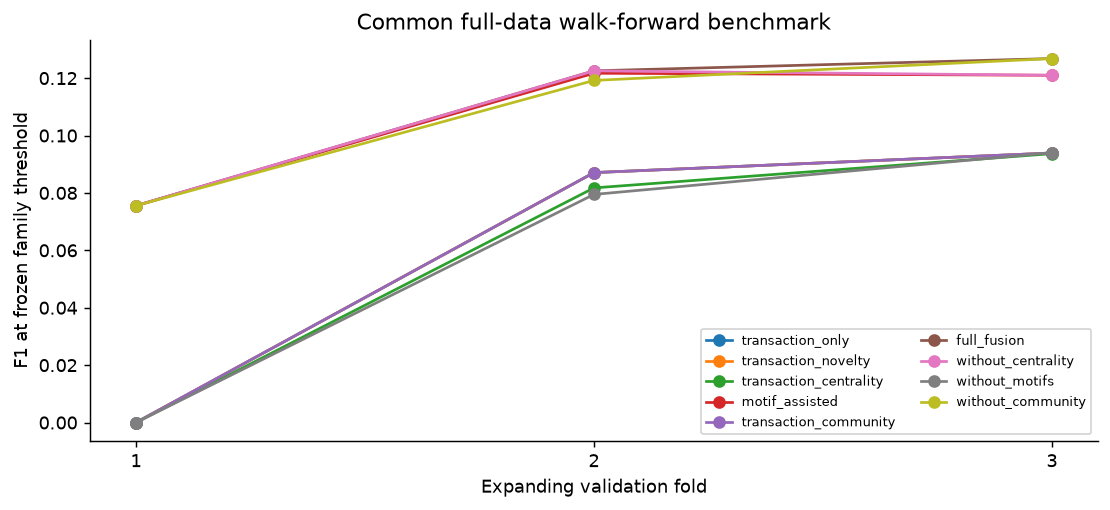

Frozen choice: full_fusion 0.5


In [29]:
import hashlib
import json
import time
from src.motif.pipeline import _reuse_system_phase, _finish_system_phase, _records
from src.motif.modeling import prepare_training_prefix, fit_prepared_model, score_histogram, choose_walk_forward_rule
from src.motif.presentation import plot_system_validation

def full_system_validation(run):
    """All eight families see identical rows, folds and declared tuning budget."""
    reused = _reuse_system_phase(run, "validation")
    if reused is not None:
        return reused
    from src.motif.config import SYSTEM_FAMILY_GROUPS
    from src.motif.evaluation import require_unlabelled
    started = time.perf_counter()
    features = run.table("features")
    require_unlabelled(features)
    truth = run.table("transactions").select("event_id", "isFraud")
    boundaries = run.record["snapshot_cutoffs"][1:]
    records, aps = [], []
    for fold, (start, end) in enumerate(zip(boundaries[:-1], boundaries[1:]), 1):
        prepared = run.kernel("prepare_training_prefix", prepare_training_prefix)(
            features, truth, start, run.config.analysis, spill_training=True)
        try:
            for family in SYSTEM_FAMILY_GROUPS:
                print(f"[SYSTEM] Validation {fold}/3: {family}, train<={start}, validation<={end}", flush=True)
                model = run.kernel("fit_prepared_model", fit_prepared_model)(prepared, family, run.config.analysis)
                interval = features.where((F.col("step") > start) & (F.col("step") <= end))
                scores = run.kernel("score_transactions", score_transactions)(model, interval)
                histogram = score_histogram(scores, truth, start, end)
                curve, ap = run.kernel("precision_recall_curve", precision_recall_curve)(histogram)
                aps.append({"fold": fold, "family": family, "average_precision": ap,
                            "transactions": int(histogram["count"].sum())})
                for threshold in run.config.analysis.score_thresholds:
                    records.append({"fold": fold, "family": family, "threshold": threshold,
                                    **run.kernel("metrics_at_threshold", metrics_at_threshold)(histogram, threshold)})
        finally:
            prepared.close()
    folds = pd.DataFrame(records)
    counts = folds.groupby("fold").transactions.nunique()
    if not (counts == 1).all():
        raise ValueError("Ablation validation populations differ")
    selection, leaderboard = choose_walk_forward_rule(folds)
    rules = {name: _records(leaderboard[leaderboard.family == name].head(1))[0] for name in SYSTEM_FAMILY_GROUPS}
    payload = {"selection": _records(pd.DataFrame([selection]))[0], "family_rules": rules,
               "selection_criterion": "mean validation F1; worst-fold F1, fewer FP, simpler family, higher threshold ties"}
    digest = hashlib.sha256(json.dumps(payload, sort_keys=True, allow_nan=False).encode()).hexdigest()
    (run.output_dir / "frozen_rules.json").write_text(json.dumps({**payload, "sha256": digest}, indent=2, allow_nan=False)+"\n", encoding="utf-8")
    folds.to_csv(run.output_dir / "walk_forward.csv", index=False, encoding="utf-8-sig")
    leaderboard.to_csv(run.output_dir / "validation_leaderboard.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame(aps).to_csv(run.output_dir / "validation_average_precision.csv", index=False, encoding="utf-8-sig")
    run.record["frozen_rule_sha256"] = digest
    _finish_system_phase(run, "validation", started, {"selection": payload["selection"], "families": len(rules), "folds": 3})
    return leaderboard

leaderboard = full_system_validation(run)
family_rules = json.loads((run.output_dir/'frozen_rules.json').read_text(encoding='utf-8'))
validation_view = pd.DataFrame(family_rules['family_rules']).T.reset_index(drop=True)
display(validation_view[['family','threshold','mean_F1','worst_F1','std_F1','TP','FP','FN']])
_ = plot_system_validation(run)
print('Frozen choice:', family_rules['selection']['family'], family_rules['selection']['threshold'])

## 11 · Refit tới80% → frozen test → predictions

Refit9 families trên cùng prefix cuối. Mỗi test transaction có đúng một score/alert mỗi family. Export model/scales/predictions, rồi reload selected model và replay **toàn test**. Bảng dưới giữ đủ9đối chứng trên cùng mẫu số.

In [30]:
from src.motif.pipeline import full_system_test
from src.motif.presentation import system_phase_table

metrics = full_system_test(run)
assert metrics.transactions.nunique() == metrics.fraud.nunique() == 1
display(metrics[['model','threshold','TP','FP','FN','TN','F1']])
display(metrics[['model','precision','recall','average_precision','alert_rate','selected_on_validation']])
display(system_phase_table(run, 'frozen_test'))

[SYSTEM] Frozen refit/test: transaction_only
[SYSTEM] Frozen refit/test: transaction_novelty
[SYSTEM] Frozen refit/test: transaction_centrality
[SYSTEM] Frozen refit/test: motif_assisted
[SYSTEM] Frozen refit/test: transaction_community
[SYSTEM] Frozen refit/test: full_fusion
[SYSTEM] Frozen refit/test: without_centrality
[SYSTEM] Frozen refit/test: without_motifs
[SYSTEM] Frozen refit/test: without_community

[SYSTEM] frozen_test: PASS


,model,threshold,TP,FP,FN,TN,F1
0,transaction_only,0.5,869,8715,930,1007307,0.152684
1,transaction_novelty,0.5,869,8715,930,1007307,0.152684
2,transaction_centrality,0.5,884,8780,915,1007242,0.154235
3,motif_assisted,0.5,465,3894,1334,1012128,0.151023
4,transaction_community,0.5,869,8715,930,1007307,0.152684
5,full_fusion,0.5,500,4456,1299,1011566,0.148038
6,without_centrality,0.5,465,3894,1334,1012128,0.151023
7,without_motifs,0.5,905,9338,894,1006684,0.150307
8,without_community,0.5,479,3896,1320,1012126,0.155167


,model,precision,recall,average_precision,alert_rate,selected_on_validation
0,transaction_only,0.090672,0.483046,0.056203,0.009416,False
1,transaction_novelty,0.090672,0.483046,0.056203,0.009416,False
2,transaction_centrality,0.091474,0.491384,0.058324,0.009495,False
3,motif_assisted,0.106676,0.258477,0.056654,0.004283,False
4,transaction_community,0.090672,0.483046,0.056203,0.009416,False
5,full_fusion,0.100888,0.277932,0.058669,0.004869,True
6,without_centrality,0.106676,0.258477,0.056654,0.004283,False
7,without_motifs,0.088353,0.503057,0.059548,0.010064,False
8,without_community,0.109486,0.266259,0.058266,0.004298,False


,check,value
0,status,PASS
1,elapsed_seconds,238.956
2,average_job_cpu_percent,48.16
3,test_transactions,1017821
4,test_positives,1799
5,full_test_model_reload,PASS
6,peak_job_commit_gib,5.99
7,minimum_available_ram_gib,14.21


## 12 · Kết quả cuối: có cải thiện không, review bao nhiêu giao dịch?

Cùng một test population cho baseline, từng nhóm và ablations. PR curve/AP đo ranking; thresholdF1 và reviewTop-K là hai operating policies khác nhau. Budgets0.1/0.5/1% chọn đúngK; score ties dùng event_key rồi event_id, không dùng labels.

Các rate dùng thang0–1: ví dụ0.093 tương ứng9.3%. AP cần so cùng test prevalence; không diễn giải risk score là xác suất calibrated.

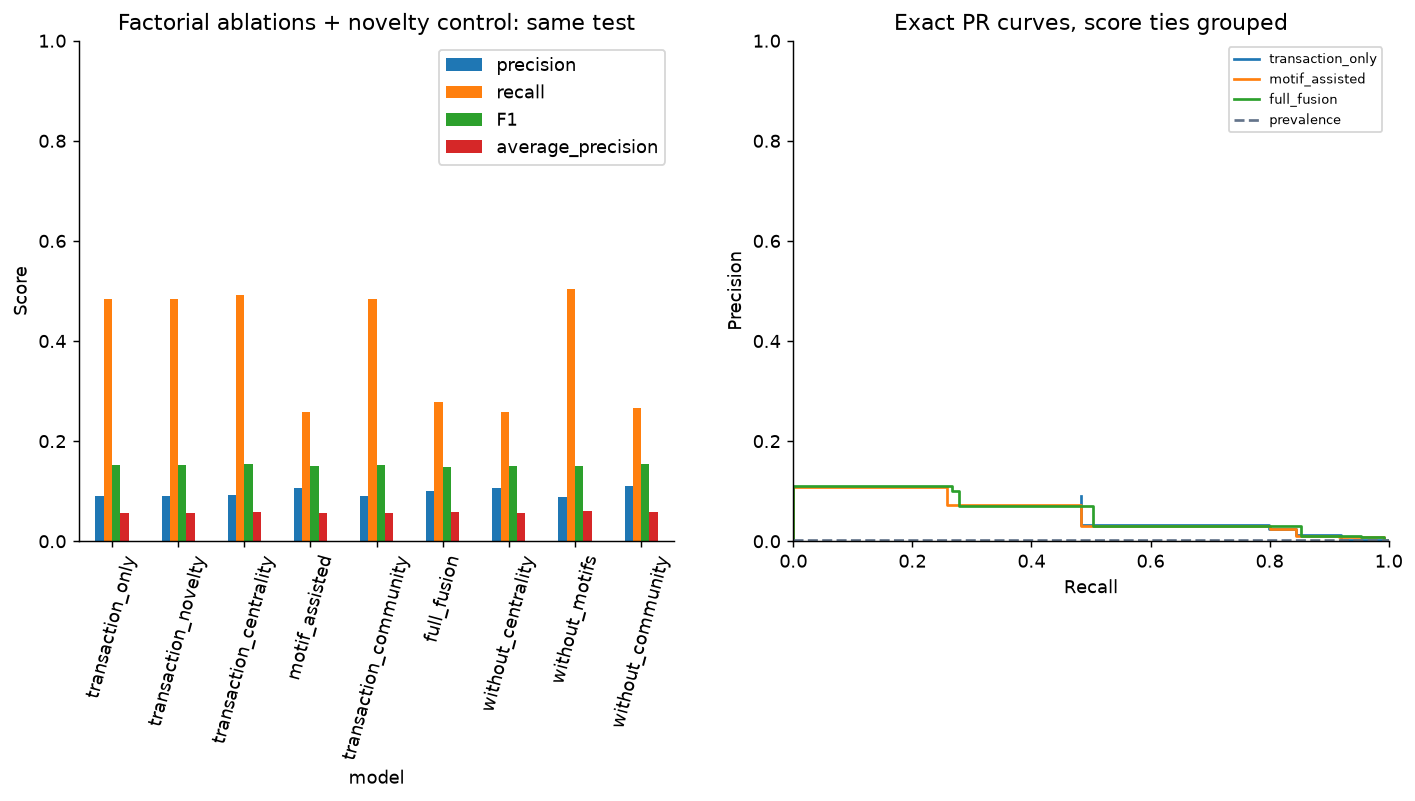

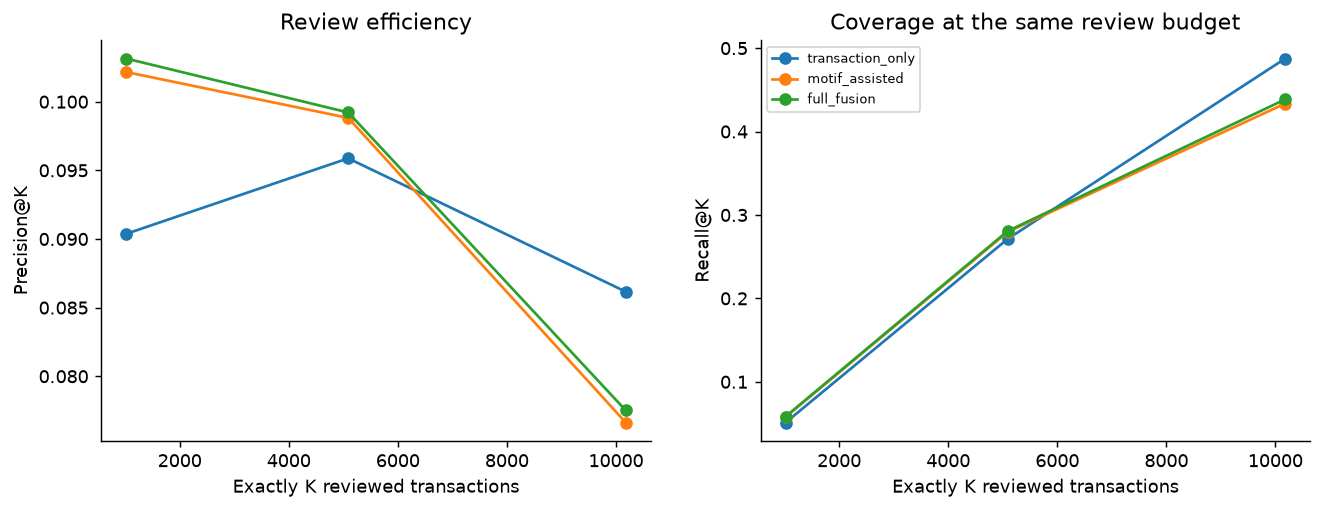

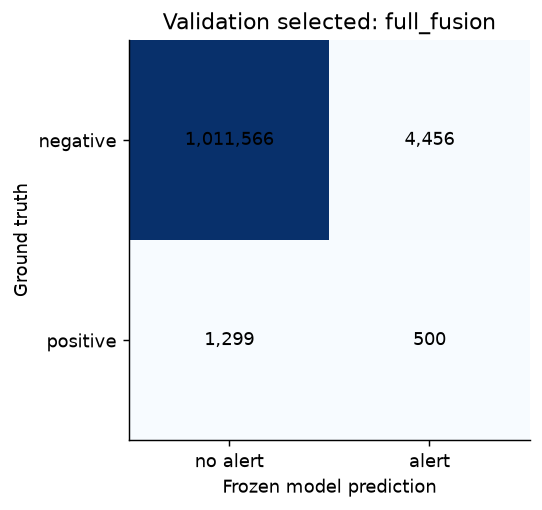

,selected_family,threshold,precision,recall,F1,average_precision
0,full_fusion,0.5,0.100888,0.277932,0.148038,0.058669


,model,review_fraction,K,TP_at_K,precision_at_K,recall_at_K
0,transaction_only,0.001,1018,92,0.090373,0.051140
1,transaction_only,0.005,5090,488,0.095874,0.271262
2,transaction_only,0.010,10179,877,0.086158,0.487493
9,motif_assisted,0.001,1018,104,0.102161,0.057810
10,motif_assisted,0.005,5090,503,0.098821,0.279600
11,motif_assisted,0.010,10179,780,0.076628,0.433574
15,full_fusion,0.001,1018,105,0.103143,0.058366
16,full_fusion,0.005,5090,505,0.099214,0.280712
17,full_fusion,0.010,10179,789,0.077513,0.438577


Selected minus baseline: ΔF1=-0.0046; ΔAP=+0.0025


In [31]:
from src.motif.presentation import plot_system_results

_ = plot_system_results(run)
selected_name = family_rules['selection']['family']
selected = run.record['selected_test_metrics']
display(pd.DataFrame([selected])[[
    'model','threshold','precision','recall','F1','average_precision']].rename(columns={'model':'selected_family'}))
budgets = pd.read_csv(run.output_dir/'review_budgets.csv')
display(budgets[budgets.model.isin(['transaction_only','motif_assisted',selected_name])][
    ['model','review_fraction','K','TP_at_K','precision_at_K','recall_at_K']])
base = metrics.set_index('model').loc['transaction_only']
print(f"Selected minus baseline: ΔF1={selected['F1']-base.F1:+.4f}; "
      f"ΔAP={selected['average_precision']-base.average_precision:+.4f}")

## 13 · Reliability: biến động, uncertainty, reproducibility

Phân biệt software correctness với predictive reliability. Báo3 validation folds,5 chronological test periods với rule đã khóa, Wilson95% cho P/R, cold-start groups, graph contribution contrasts và actual tree importance. Model replay toàn test và independent artifact checks xác nhận tái lập.

Wilson intervals chưa điều chỉnh account/time dependence; temporal periods là diagnostics, không dùng chọn lại model. Importance của cycle/relay có thể bằng0 và phải được báo thật.

### Đọc kết quả vừa chạy — `run_20261024T081350344149Z`

Selected `full_fusion`: P=10.09%, R=27.79%, F1=14.80%, AP=5.87%. Baseline: F1=15.27%, AP=5.62%. Đọc đây là trade-off thực tế; không thay lựa chọn bằng kết quả test.

F1 qua5khoảngtest: 3.32%–28.79%. Số positives của từng period được in kèm để giải thích biến động; CI tổng thể không thay kiểm tra theo thời gian.

Cycle/relay có tree importance0 trong model được chọn của run này. Group motifs còn chứa fan-in/out và reciprocal; một cycle witness thật không chứng minh cycle feature gây alert.


Nguồn đối chiếu: [src/motif/pipeline.py](../src/motif/pipeline.py) · `temporal_test_context()`. Kernel ở cell dưới được kiểm tra AST khớp source trước execution.

[SYSTEM] reliability: PASS


,model,mean_F1,worst_F1,std_F1,test_period_min_F1,test_period_max_F1,test_period_std_F1
0,transaction_only,0.060327,0.0,0.052356,0.044199,0.329914,0.117004
1,transaction_novelty,0.060327,0.0,0.052356,0.044199,0.329914,0.117004
2,transaction_centrality,0.058472,0.0,0.050988,0.044776,0.332142,0.117536
3,motif_assisted,0.106078,0.075552,0.026439,0.034985,0.297297,0.102783
4,transaction_community,0.060327,0.0,0.052356,0.044199,0.329914,0.117004
5,full_fusion,0.108301,0.075552,0.028442,0.033188,0.287898,0.098770
6,without_centrality,0.10636,0.075552,0.026692,0.034985,0.297297,0.102783
7,without_motifs,0.057839,0.0,0.050617,0.042634,0.320333,0.112864
8,without_community,0.107185,0.075552,0.027659,0.036398,0.304753,0.104943


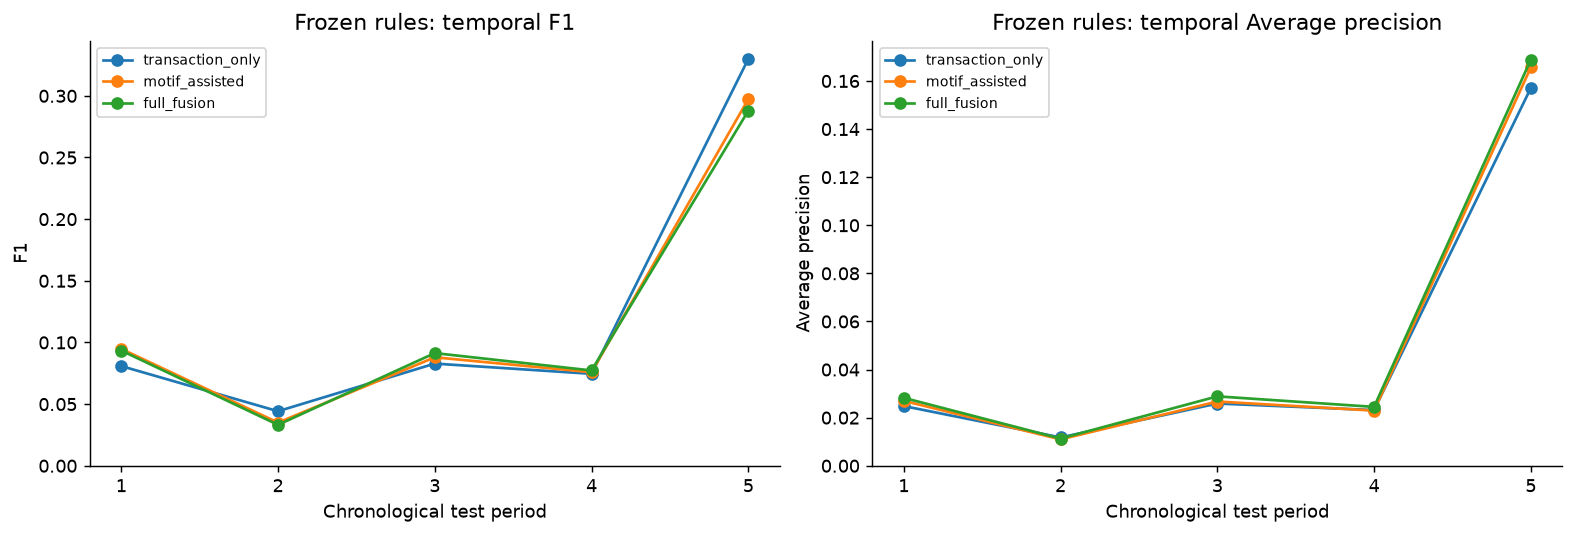

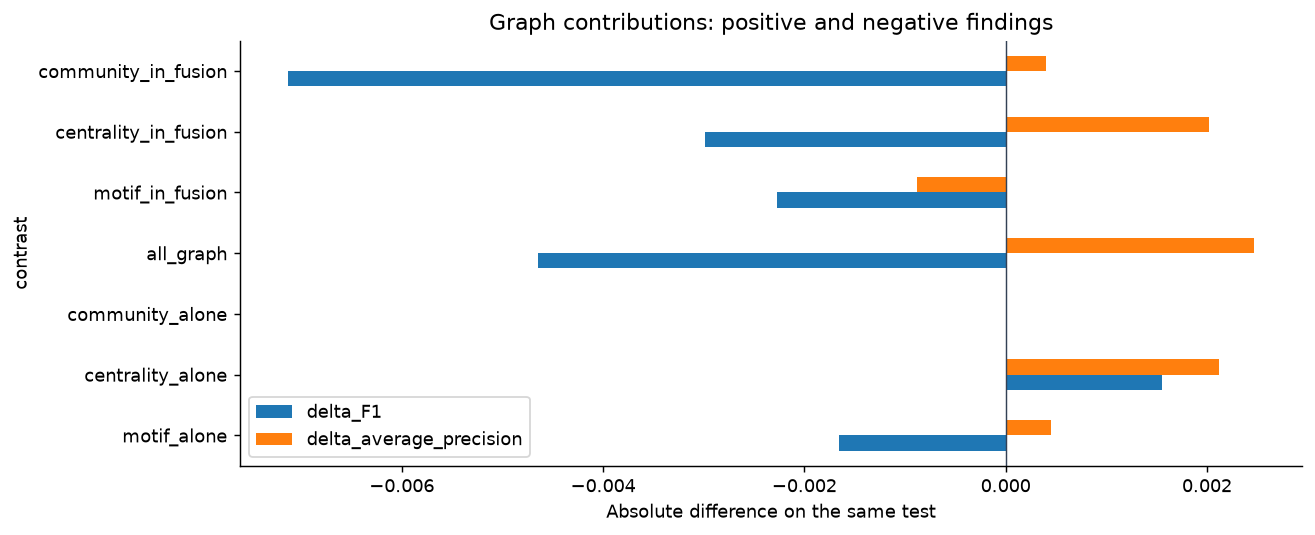

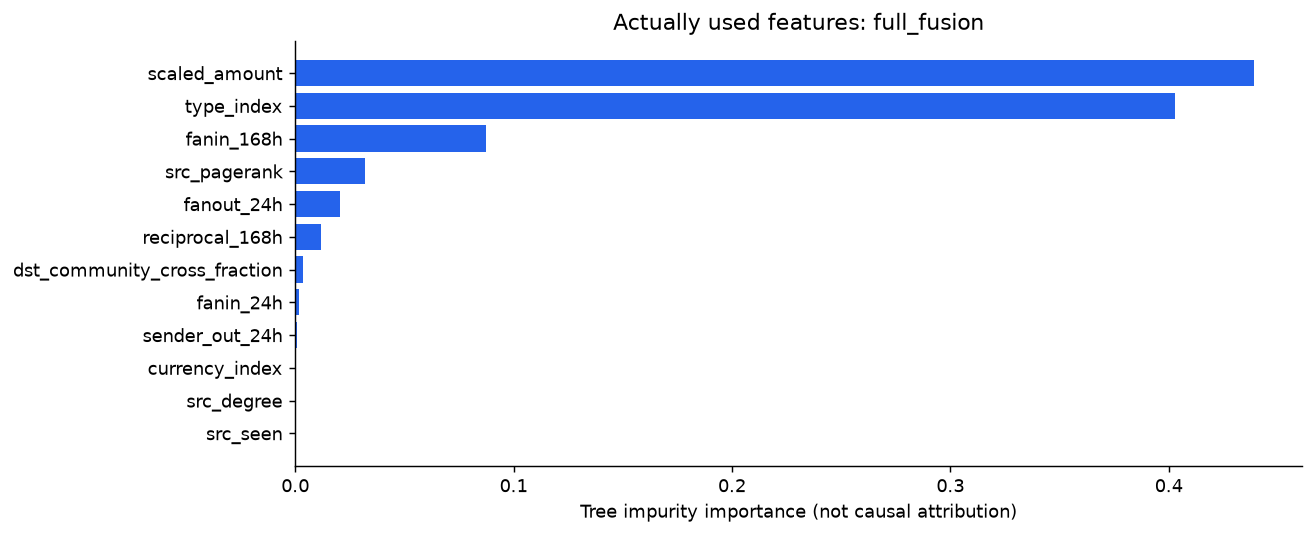

,period_zero_based,transactions,fraud,TP,FP,FN
25,0,203929,205,44,693,161
26,1,203134,141,19,985,122
27,2,203756,198,56,972,142
28,3,203828,159,42,886,117
29,4,203174,1096,339,920,757


,period_zero_based,precision,recall,F1,average_precision
25,0,0.059701,0.214634,0.093418,0.028232
26,1,0.018924,0.134752,0.033188,0.011307
27,2,0.054475,0.282828,0.091354,0.028853
28,3,0.045259,0.264151,0.077277,0.024472
29,4,0.269261,0.309307,0.287898,0.168868


,model,precision_low95,precision_high95,recall_low95,recall_high95
0,transaction_only,0.085086,0.096586,0.460015,0.506149
1,transaction_novelty,0.085086,0.096586,0.460015,0.506149
2,transaction_centrality,0.085887,0.097385,0.468326,0.514479
3,motif_assisted,0.097856,0.116189,0.238776,0.279207
4,transaction_community,0.085086,0.096586,0.460015,0.506149
5,full_fusion,0.092809,0.109584,0.257721,0.299090
6,without_centrality,0.097856,0.116189,0.238776,0.279207
7,without_motifs,0.083010,0.094005,0.479971,0.526130
8,without_community,0.100574,0.119083,0.246348,0.287166


,history_group,transactions,fraud,alerts,precision,recall,F1
0,both_seen,1015938,1745,4895,0.100102,0.280802,0.147590
1,both_unseen,68,0,1,0.000000,NaN,0.000000
2,one_unseen,1815,54,60,0.166667,0.185185,0.175439


,feature,importance
85,relay_24h,0.0
94,relay_168h,0.0
95,cycle3_count,0.0
96,cycle3_best_ratio,0.0
98,cycle3_min_gap_seconds,0.0


In [32]:
from pyspark.sql import functions as F
from src.motif.pipeline import full_system_reliability
from src.motif.presentation import plot_system_reliability

def temporal_test_context(final):
    """Five chronological test periods; all equal timestamps stay together."""
    cuts = sorted(set(int(x) for x in final.approxQuantile("step", [.2,.4,.6,.8], .001)))
    block = F.lit(0)
    for cutoff in cuts:
        block = block + (F.col("step") > cutoff).cast("int")
    return final.select("event_id", "step").withColumn("test_period", block), cuts

run.kernels['temporal_test_context'] = temporal_test_context
stability = full_system_reliability(run)
display(stability[['model','mean_F1','worst_F1','std_F1','test_period_min_F1','test_period_max_F1','test_period_std_F1']])
periods = plot_system_reliability(run)
display(periods[['period_zero_based','transactions','fraud','TP','FP','FN']])
display(periods[['period_zero_based','precision','recall','F1','average_precision']])
display(metrics[['model','precision_low95','precision_high95','recall_low95','recall_high95']])
cold_start = pd.read_csv(run.output_dir/'selected_cold_start.csv')
display(cold_start[['history_group','transactions','fraud','alerts','precision','recall','F1']])
importance = pd.read_csv(run.output_dir/'feature_importance.csv')
display(importance[(importance.family==selected_name) &
                   importance.feature.str.contains('cycle3|relay')][['feature','importance']])

## 14 · Giao dịch thật: TP, FP, FN và witness

Case được lấy sau frozen scoring. Graph chỉ vẽ các cạnh thật có witness, kèm thời gian/amount/currency/truth. Nếu không có TP hoặc không có motif witness phù hợp thì ghi rõ; không dựng vòng giả. Một graph đẹp không thay benchmark trên toàn test.

TP: selected test examples; at most 3 shown


,step,src,dst,amount,payment_currency,risk_score,isFraud
0,1662629400,23842_8019C0990,1674_8006A6CF0,17576.30,US Dollar,0.780899,1
1,1662870360,3489_801C63740,1601_80340DCF0,10861.49,US Dollar,0.780899,1
2,1662889440,222268_8083A8800,1412_801434090,14094.27,US Dollar,0.780899,1


FP: selected test examples; at most 3 shown


,step,src,dst,amount,payment_currency,risk_score,isFraud
0,1662755700,138395_80F6139C0,240229_80F613AB0,160.28,Swiss Franc,0.879032,0
1,1662724560,11318_80BB1CB80,23833_80BB1CBD0,1108.37,US Dollar,0.879032,0
2,1662666960,2952_804CDB520,4766_804CDB5C0,483.42,US Dollar,0.879032,0


FN: selected test examples; at most 3 shown


,step,src,dst,amount,payment_currency,risk_score,isFraud
0,1663033560,249176_812A70ED0,49508_812A70E80,43845.91,Saudi Riyal,0.376515,1
1,1662631980,20226_80857D940,241775_810DCEAA0,15240.55,Euro,0.376515,1
2,1662700020,3051_804282480,27217_806453860,5500.84,Euro,0.376515,1


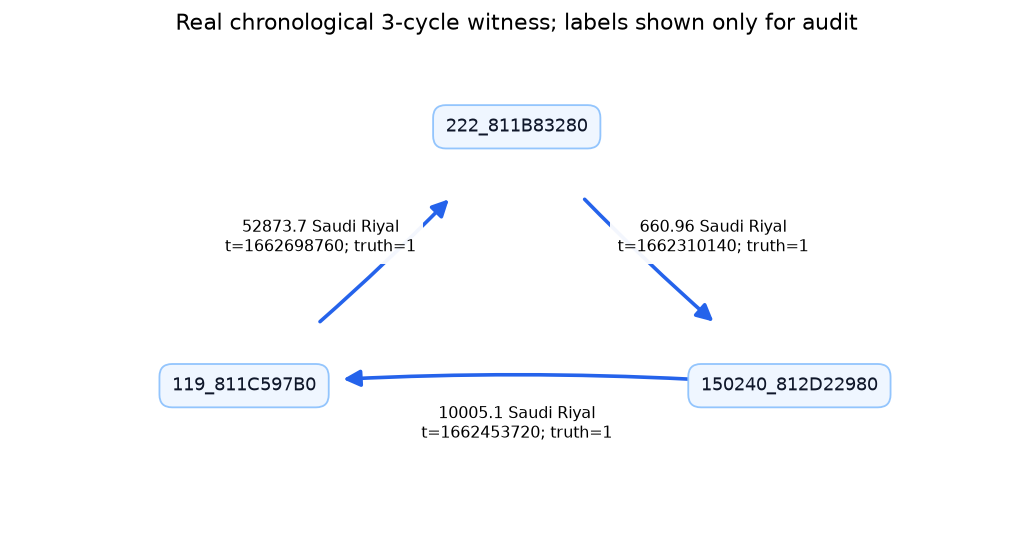

Witness: chronological 3-cycle witness


,time,src,dst,amount,payment_currency,isFraud
0,2022-09-04 16:49 UTC,222_811B83280,150240_812D22980,660.96,Saudi Riyal,1.0
1,2022-09-06 08:42 UTC,150240_812D22980,119_811C597B0,10005.08,Saudi Riyal,1.0
2,2022-09-09 04:46 UTC,119_811C597B0,222_811B83280,52873.69,Saudi Riyal,1.0


In [33]:
from src.motif.presentation import system_case_evidence

for case in ('TP','FP','FN'):
    examples = pd.read_json(run.output_dir/f'examples_{selected_name}_{case}.json') if selected_name!='abstain' else pd.DataFrame()
    print(f'{case}: selected test examples; at most 3 shown')
    columns = [c for c in ['step','src','dst','amount','payment_currency','risk_score','isFraud']
               if c in examples.columns]
    display(examples[columns].head(3))
evidence = system_case_evidence(run)
if 'step' in evidence.columns:
    shown = evidence.copy()
    shown['time'] = (pd.to_datetime(shown.step,unit='s',utc=True).dt.strftime('%Y-%m-%d %H:%M UTC')
                     if DATASET=='ibm_aml' else shown.step)
    print('Witness:', shown.evidence_kind.iloc[0])
    display(shown[['time','src','dst','amount','payment_currency','isFraud']])
else:
    display(evidence)

## 15 · Kiểm tra độc lập và benchmark thực thi

Verifier stream predictions để tính lại confusion/AP, kiểm tra full coverage, raw/input/source/output hashes và snapshot timing. Chỉ publish local latest khi PASS. Bảng thời gian/CPU/commit dưới đây là measurement của run; không lấy host CPU của ứng dụng khác làm CPU của job.

In [34]:
from src.motif.pipeline import finalize_full_system
from src.motif.presentation import system_execution_benchmark

acceptance = finalize_full_system(run)
display(acceptance)
display(system_execution_benchmark(run))
print('Acceptance is software/data integrity; predictive quality is the measured benchmark above.')

,check,result
0,status,PASS
1,scope,full
2,full_transactions,5078345
3,full_accounts,518581
4,models,9
5,test_transactions,1017821
6,test_positives,1799
7,predictions_confusion_and_AP,independently recomputed
8,artifact_hashes,PASS


,phase,seconds,job_CPU_percent,peak_commit_GiB,minimum_host_free_GiB
0,raw_reconciliation,66.024,46.50,5.22,14.40
1,centrality_full,39.927,35.67,5.23,14.27
2,communities_full,69.736,38.32,5.24,14.27
3,motif_baseline,11.112,41.39,5.24,14.27
4,motif_features,149.841,62.50,6.21,13.39
5,motif_benchmark,7.586,50.67,6.21,13.39
6,common_features,749.761,41.18,6.27,13.39
7,validation,427.915,50.93,6.27,13.39
8,frozen_test,238.956,48.16,5.99,14.21
9,reliability,7.449,11.21,5.99,14.21


Acceptance is software/data integrity; predictive quality is the measured benchmark above.


In [35]:
from src.common.hardware_guard import protection_snapshot

# Đóng Spark sau khi lưu mọi output; runner đóng kernel và dọn JVM tree.
display(session.close())

,setting,value
0,dataset,ibm_aml
1,finished_utc,2026-10-24T08:46:38.834981+00:00
2,elapsed_seconds,287.7
3,execution,Completed; performance is reported separately
4,cpu_hard_cap_percent,100
5,max_logical_cpus,20
6,spark_task_slots,20
7,job_cpu_seconds,2506.953
8,job_wall_seconds,287.734
9,average_job_cpu_percent,43.56


## Kết luận trong đúng phạm vi

Đánh giá `laundering` ở cấp giao dịch trên IBM AML HI-Small; không gộp F1 giữa hai datasets. Full fusion cần được so với baseline và leave-one-group-out bằng các số vừa chạy. Nhãn community, motif count và risk score mang ý nghĩa khác nhau. Test đã được dùng trong lịch sử project; cần external holdout mới để kết luận khả năng tổng quát hóa.